In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.home() / "projects" / "poreallas"
sys.path.insert(0, str(PROJECT_ROOT))

import importlib
import os

import pandas as pd
import numpy as np
import xarray as xr
from dotenv import find_dotenv, load_dotenv
from datetime import datetime, UTC

from utils import analysis_utils, isku_utils, plotting_utils

importlib.reload(analysis_utils)
importlib.reload(isku_utils)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


<module 'utils.isku_utils' from '/home/emily_zuetell/projects/poreallas/utils/isku_utils.py'>

In [15]:
RUN_MONTH = "2026-10"
N_LEADS = 6

_months = pd.period_range(pd.Period(RUN_MONTH, "M"), periods=N_LEADS, freq="M")
FC_MONTHS = [p.month for p in _months]
FC_PERIOD = slice(
    _months[0].start_time.strftime("%Y-%m-%d"),
    _months[-1].end_time.strftime("%Y-%m-%d"),
)

# Baseline period for Impact
BASELINE_PERIOD = slice("1996-01-01", "2025-12-31")


config = analysis_utils.ImpactConfig(
    version=f"v{datetime.now(tz=UTC):%y%m%d}",
    baseline_period=BASELINE_PERIOD,
    polygons_path=os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
    socioeconomics_path=os.environ["POREALLAS_SOCIOECONOMICS_URI"],
    rate=False,
    months=FC_MONTHS,
    hotonly="hotonly",
    dims=["number", "sample"],
)

In [2]:
forecast = xr.open_zarr("/home/emily_zuetell/projects/poreallas/data/v2609/v20260909_forecast_adj.zarr")
era5_running = xr.open_zarr("/home/emily_zuetell/projects/poreallas/data/2609_era5_running_adj.zarr")

In [53]:
fc_9 = forecast.sel(time = slice('2026-09-02', '2026-09-30')).mean(dim = 'number').mean(dim = 'time')
era5_9 = era5_running.sel(time = slice('2026-09-02', '2026-09-30')).mean(dim = 'time')

In [54]:
diff = era5_9-fc_9

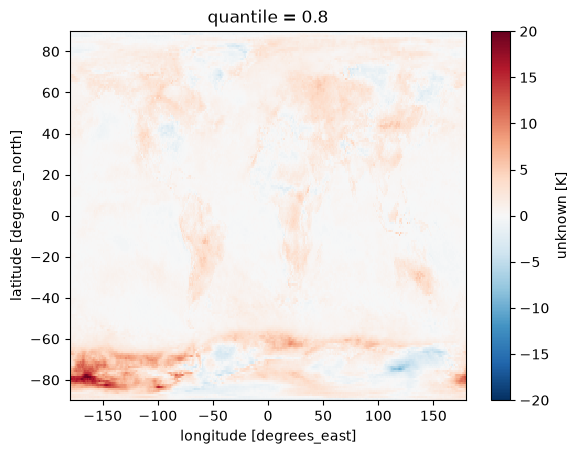

In [46]:
diff['tas'].plot()

In [55]:

# Gridded to Impact Region
forecast_ir = isku_utils.grid_to_ir(diff, savefile=None)
diff_pop = forecast_ir * config.socioeconomics['pop']

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3413: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


In [56]:
_polygons_forecast = analysis_utils.xarray_to_gpd(forecast_ir["tas"], config.polygons)

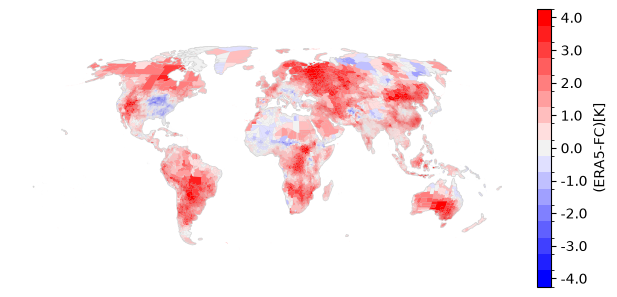

In [49]:
fig = plotting_utils.plot_single(
    _polygons_forecast,
    col="tas",
    n_colors = 15,
    cm="bwr",
    sup_title="",
    cbar_label="(ERA5-FC)[K]",
)

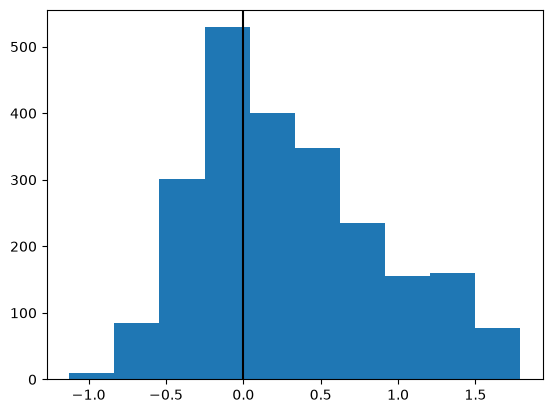

In [64]:
plt.hist(_polygons_forecast[_polygons_forecast['ISO']=='IND']['tas'].values)
plt.axvline(0, color = 'k')

In [29]:
import matplotlib.pyplot as plt

Text(0, 0.5, 'density')

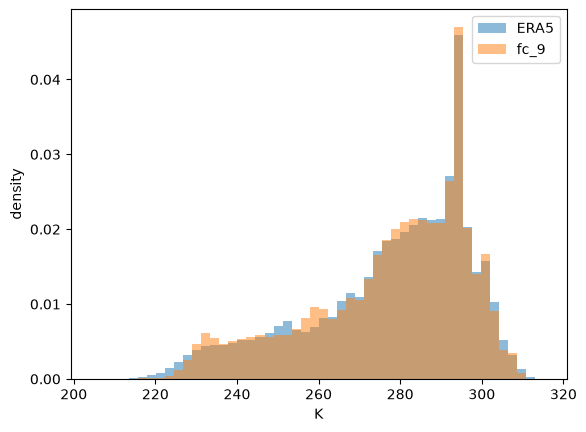

In [34]:
da1 = era5_running.sel(time = slice('2026-09-02', '2026-09-30'))['tas']
da2 = forecast.sel(time = slice('2026-09-02', '2026-09-30')).mean(dim = 'number')['tas']

a_vals = da1.values.ravel()
b_vals = da2.values.ravel()
a_vals = a_vals[~np.isnan(a_vals)]
b_vals = b_vals[~np.isnan(b_vals)]

bins = np.histogram_bin_edges(np.concatenate([a_vals, b_vals]), bins=50)

plt.hist(a_vals, bins=bins, alpha=0.5, label= "ERA5", density=True)
plt.hist(b_vals, bins=bins, alpha=0.5, label="fc_9", density=True)
plt.legend()
plt.xlabel(da1.attrs.get("units", "value"))
plt.ylabel("density")